# Лабораторна робота №3

**Інтелектуальний аналіз даних та моделювання кризових явищ**  
Токарчук Роман, група 507.

**Тема:** регресія, класифікація табличних даних і текстів.

**Статус: виконано 3 з 5 основних задач.** CO₂, heart.csv та відгуки Coursera виконано. Для морозива й енергоспоживання очікуються оригінальні файли викладача; ці два пункти не позначені як завершені. Код доступних частин — у [lab3.py](lab3.py).

## Дані й оцінювання

Оригінальні CO₂ та heart.csv взято з репозиторію викладача. Для текстів завантажено рекомендований Kaggle-набір **100K Coursera’s Course Reviews**, файл `reviews.csv`. Джерела й SHA-256 — у `resources/lab3_sources.json`.

Окремі **20%** даних залишено для validation, `random_state=42`. Модель та її параметри обираються крос-валідацією лише на решті 80%. Масштабування, кодування категорій і TF-IDF включені в Pipeline та навчаються всередині фолдів. Validation не бере участі у виборі моделі. Підсумкові оцінки стосуються цього відкладеного набору, а не незалежної зовнішньої перевірки.

Після встановлення спільних залежностей усі доступні частини працюють без інтернету.

In [1]:
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
from lab3 import (ROOT, OUTPUTS, FIGURES, extract_texts_from_file, build_plot,
                  CO2_emissions, heart_classification, load_dataset, classify_text_ml, write_summary)

def read_result(name):
    return json.loads((OUTPUTS / name).read_text(encoding="utf-8"))

print("Доступні оригінальні файли:")
for filename in ["CO2_emission.csv", "heart.csv", "reviews.csv",
                 "ice_cream_selling_data.csv", "powerconsumption.csv"]:
    print(filename, "—", "є" if (ROOT / "resources" / filename).exists() else "очікується від викладача")

Доступні оригінальні файли:
CO2_emission.csv — є
heart.csv — є
reviews.csv — є
ice_cream_selling_data.csv — очікується від викладача
powerconsumption.csv — очікується від викладача


## Читання CSV

Назву `extract_texts_from_file()` збережено зі стартового шаблону. Тут дані табличні, тому функція повертає **pandas.DataFrame**, а не список текстів. Таблиця зберігає назви колонок і числові типи, потрібні моделям.

In [2]:
heart_data = extract_texts_from_file("resources/heart.csv")
display(heart_data.head())
print("Рядків і колонок:", heart_data.shape)
print("Пропусків:", int(heart_data.isna().sum().sum()))
print("Точних повторів:", int(heart_data.duplicated().sum()))

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


Рядків і колонок: (303, 14)
Пропусків: 0
Точних повторів: 1


## CO2 emissions

Process file `CO2_emission.csv`. Build a model, that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

### Реалізація

Використовується тільки `Engine_Size`; інші характеристики автомобіля не додаються. Порівняно лінійну, квадратичну та кубічну регресії через `PolynomialFeatures` і `LinearRegression`. Для вибору — найменша середня RMSE у 5-фолдовій CV на train.

На validation обчислено **MAE** — середню абсолютну похибку, **RMSE** — корінь середньої квадратичної похибки, **R²** — коефіцієнт детермінації. Похибки вимірюються в г/км. Також показано baseline, який завжди прогнозує середній CO₂ навчальної частини. Повертається список θ: вільний член і коефіцієнти степенів Engine_Size у зазначеному порядку.

Розмір: (935, 12)


,Engine_Size,CO2_Emissions
count,935.000000,935.000000
mean,3.214866,258.529412
std,1.388513,64.442768
min,1.000000,94.000000
25%,2.000000,213.000000
50%,3.000000,255.000000
75%,4.000000,303.500000
max,8.000000,608.000000


,model,degree,cv_rmse_mean,cv_rmse_std
0,polynomial_degree_3,3,35.615622,3.223031
1,polynomial_degree_1,1,35.988970,3.236120
2,polynomial_degree_2,2,36.182742,3.554811


,модель,MAE,RMSE,R²
0,Обрана,27.706067,36.977822,0.660555
1,Середнє train,51.407468,64.032630,-0.017863


,term,coefficient
0,intercept,19.069645
1,Engine_Size,140.038522
2,Engine_Size^2,-25.978945
3,Engine_Size^3,2.010351


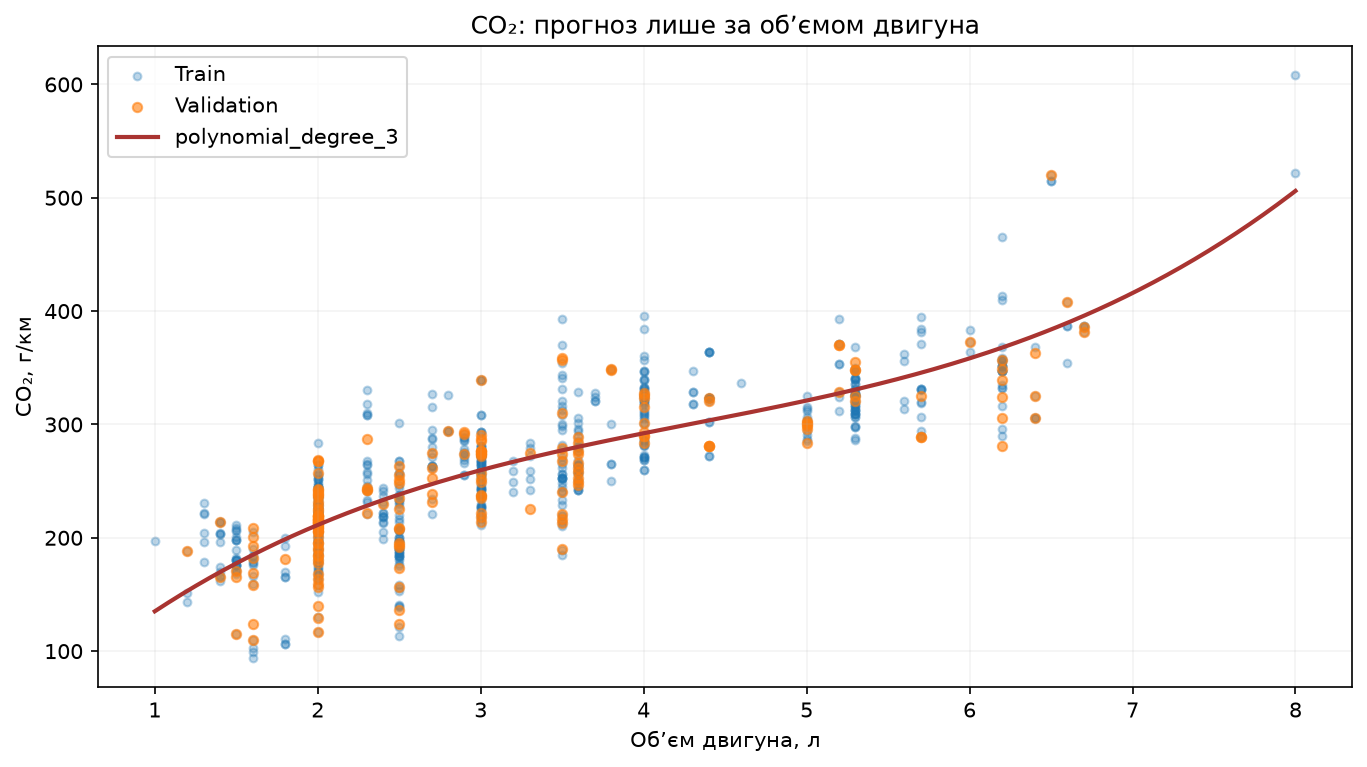

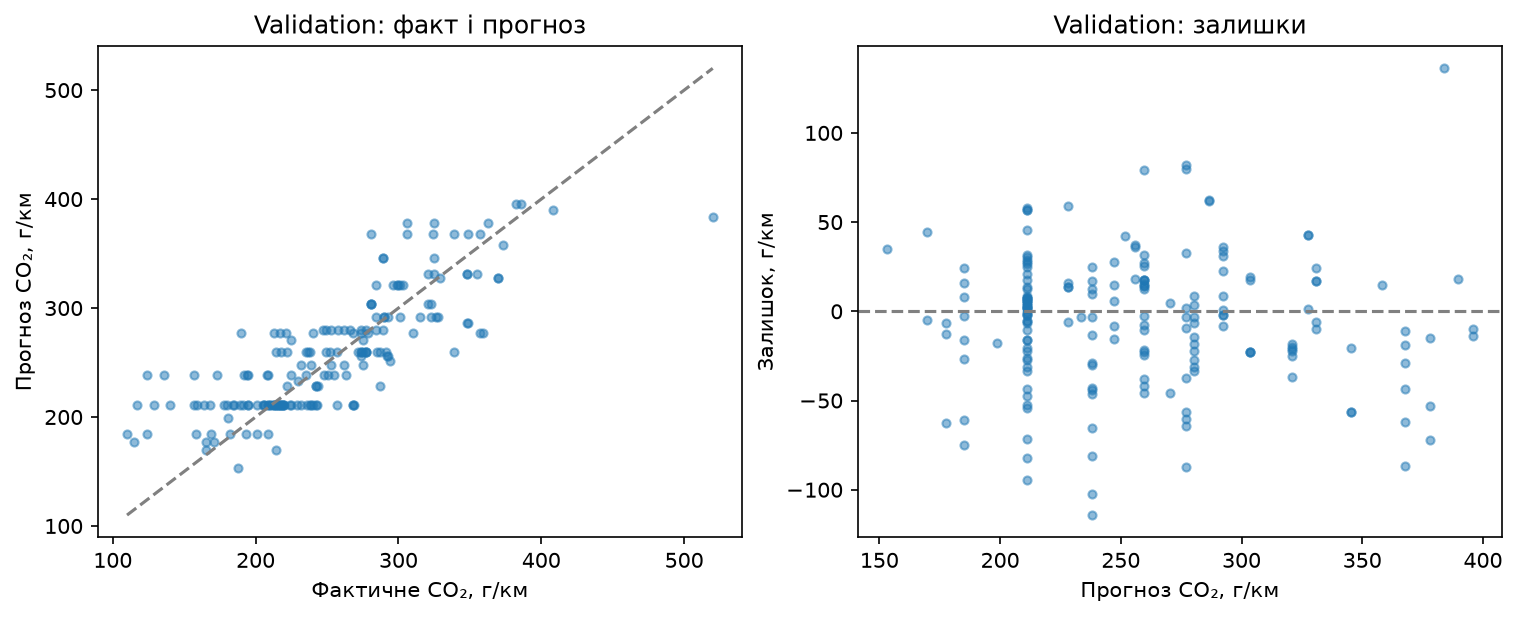

In [3]:
co2_data = extract_texts_from_file("resources/CO2_emission.csv")
print("Розмір:", co2_data.shape)
display(co2_data[["Engine_Size", "CO2_Emissions"]].describe())
theta_co2 = CO2_emissions(co2_data)
co2_summary = read_result("co2_summary.json")
display(pd.read_csv(OUTPUTS / "co2_model_selection.csv"))
display(pd.DataFrame({"модель": ["Обрана", "Середнє train"],
                      "MAE": [co2_summary["validation"]["mae"], co2_summary["baseline"]["mae"]],
                      "RMSE": [co2_summary["validation"]["rmse"], co2_summary["baseline"]["rmse"]],
                      "R²": [co2_summary["validation"]["r2"], co2_summary["baseline"]["r2"]]}))
display(pd.read_csv(OUTPUTS / "co2_coefficients.csv"))
display(Image(filename=str(FIGURES / "co2_model.png")))
display(Image(filename=str(FIGURES / "co2_validation.png")))

### Перевірка формули та прогноз

За коефіцієнтами можна незалежно від sklearn обчислити прогноз. Нижче — приклади для об’ємів двигуна всередині діапазону даних. Це обчислені оцінки моделі, а не додані спостереження.

In [4]:
validation_co2 = pd.read_csv(OUTPUTS / "co2_validation.csv")
x = validation_co2.Engine_Size.to_numpy()
manual_predictions = sum(coefficient * x**power for power, coefficient in enumerate(theta_co2))
np.testing.assert_allclose(manual_predictions, validation_co2.predicted, atol=1e-8)
new_sizes = np.array([1.5, 2.0, 3.5])
new_predictions = sum(coefficient * new_sizes**power for power, coefficient in enumerate(theta_co2))
display(pd.DataFrame({"Об’єм двигуна, л": new_sizes, "Прогноз CO₂, г/км": new_predictions}))
print("Обрано:", co2_summary["selected_model"])

,"Об’єм двигуна, л","Прогноз CO₂, г/км"
0,1.5,177.459736
1,2.0,211.313715
2,3.5,277.156179


Обрано: polynomial_degree_3


### Інтерпретація

Об’єм двигуна пояснює лише частину відмінностей CO₂. Залишки показують розкид, який одна ознака не враховує. Перевагу полінома над лінійною моделлю потрібно оцінювати разом із розкидом CV-похибки; мала різниця середніх не доводить стійкої переваги. Поліном не слід екстраполювати за межі спостережуваних об’ємів двигуна.

## Ice Cream Sales

Process file `ice_cream_selling_data.csv`. Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

### Очікується файл викладача

`resources/ice_cream_selling_data.csv` відсутній в обох наданих репозиторіях. За рішенням користувача очікуємо оригінальний файл. Модель не навчалася, коефіцієнтів і результатів для цього пункту поки немає.

In [5]:
print("Ice Cream Sales: НЕ ВИКОНАНО — очікується ice_cream_selling_data.csv від викладача.")

Ice Cream Sales: НЕ ВИКОНАНО — очікується ice_cream_selling_data.csv від викладача.


## Electric Power Consumption

Process file `powerconsumption.csv`. Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

### Очікується файл викладача

`resources/powerconsumption.csv` відсутній в обох наданих репозиторіях. Після його отримання буде перевірено структуру, цільову колонку та наявність часових міток для коректного поділу. Модель не навчалася; зовнішній набір або вигадані значення не підставлялися.

In [6]:
print("Electric Power Consumption: НЕ ВИКОНАНО — очікується powerconsumption.csv від викладача.")

Electric Power Consumption: НЕ ВИКОНАНО — очікується powerconsumption.csv від викладача.


## Heart Conditions Predictions

Process file `heart.csv`. It has the following data:

- age - Age of the patient
- sex - Sex of the patient
- cp - Chest pain type ~ 0 = Typical Angina, 1 = Atypical Angina, 2 = Non-anginal Pain, 3 = Asymptomatic
- trtbps - Resting blood pressure (in mm Hg)
- chol - Cholestoral in mg/dl fetched via BMI sensor
- fbs - (fasting blood sugar > 120 mg/dl) ~ 1 = True, 0 = False
- restecg - Resting electrocardiographic results ~ 0 = Normal, 1 = ST-T wave normality, 2 = Left ventricular hypertrophy
- thalachh - Maximum heart rate achieved
- oldpeak - Previous peak
- slp - Slope
- caa - Number of major vessels
- thall - Thalium Stress Test result ~ (0,3)
- exng - Exercise induced angina ~ 1 = Yes, 0 = No
- output - Target variable - risk of heart attack - 1 is high chance of heart attack and 0 is low chance.

Use classification model (choose model best fitting model yourself). Choose parameters that would best fit for making a prediction on. Visualize model on a plot.

Do not forget to split data into train data and validation data. Validate your model.

### Реалізація

Один точний повтор рядка видалено **до поділу**. Ціль — `output`, усі 13 інших колонок є ознаками; `output` не потрапляє у вхід моделі.

Для age, trtbps, chol, thalachh, oldpeak використано StandardScaler. Коди sex, cp, fbs, restecg, exng, slp, caa, thall обробляються як категорії через OneHotEncoder. SimpleImputer включено в конвеєр для пропусків; у наданому файлі їх немає.

Стратифікований поділ зберігає пропорції класів. Порівняно LogisticRegression, RidgeClassifier та SGDClassifier з кількома значеннями регуляризації. Обрано найбільшу macro F1 у 5-фолдовій CV на train. Після цього один раз оцінено validation: accuracy, macro/weighted F1, ROC-AUC та classification report.

Модель відтворює мітку `output` цього датасету. Її оцінки не є відкаліброваною клінічною ймовірністю інфаркту або перевіркою на новій лікарні. Повернуті θ належать до масштабованого й закодованого простору ознак; відповідність назв і коефіцієнтів збережено окремо.

Обрана модель: LogisticRegression
Параметри: {'classifier': LogisticRegression(max_iter=2000, random_state=42), 'classifier__C': 0.1}
Розмір train / validation: 241 / 61


,model,cv_macro_f1,cv_std
0,{'classifier': LogisticRegression(max_iter=200...,0.861278,0.047229
1,"{'classifier': SGDClassifier(loss='log_loss', ...",0.861097,0.041439
2,{'classifier': LogisticRegression(max_iter=200...,0.856962,0.040895
3,"{'classifier': RidgeClassifier(), 'classifier_...",0.848470,0.045114
4,"{'classifier': RidgeClassifier(), 'classifier_...",0.848155,0.053071
5,"{'classifier': RidgeClassifier(), 'classifier_...",0.844232,0.043406
6,{'classifier': LogisticRegression(max_iter=200...,0.831828,0.035391
7,"{'classifier': SGDClassifier(loss='log_loss', ...",0.810733,0.056156
8,"{'classifier': SGDClassifier(loss='log_loss', ...",0.798035,0.030693


accuracy             0.852459
macro_f1             0.849877
weighted_f1          0.851491
baseline_accuracy    0.540984
baseline_macro_f1    0.351064
roc_auc              0.892857
Name: Значення, dtype: float64

,class,precision,recall,f1-score,support
0,0,0.880000,0.785714,0.830189,28.0
1,1,0.833333,0.909091,0.869565,33.0
2,macro avg,0.856667,0.847403,0.849877,61.0
3,weighted avg,0.854754,0.852459,0.851491,61.0


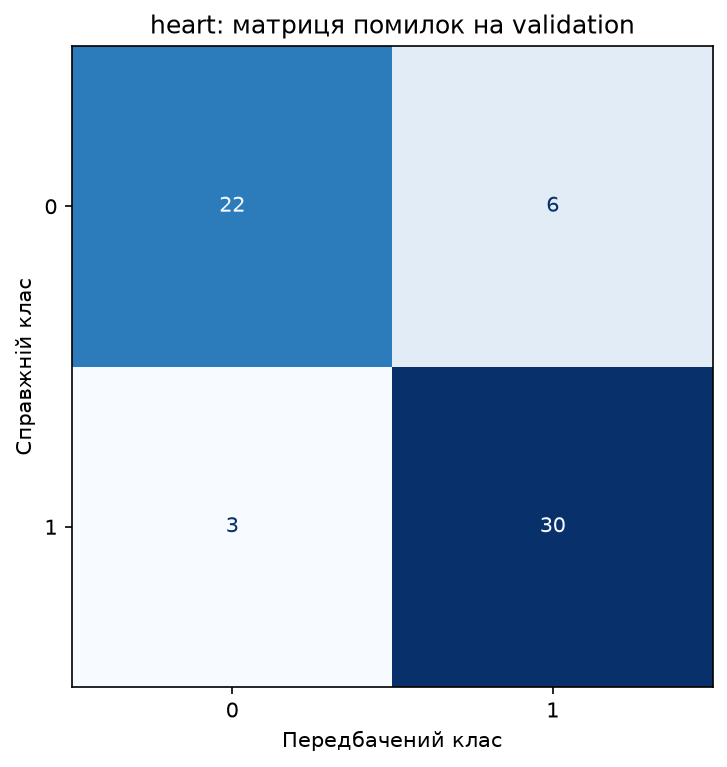

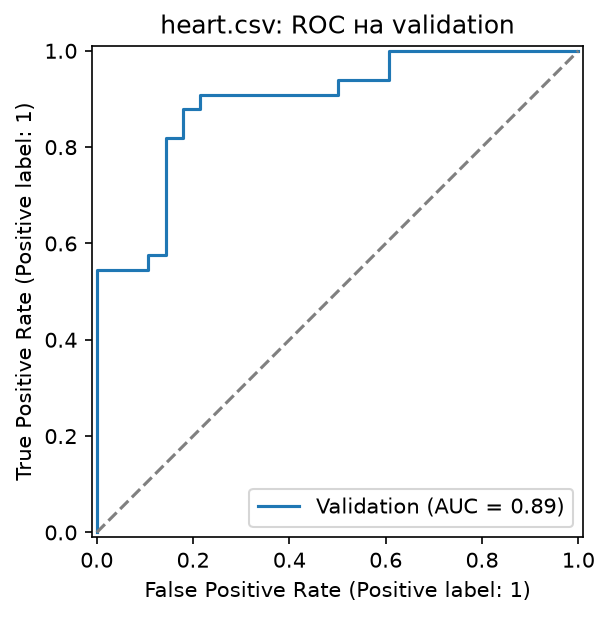

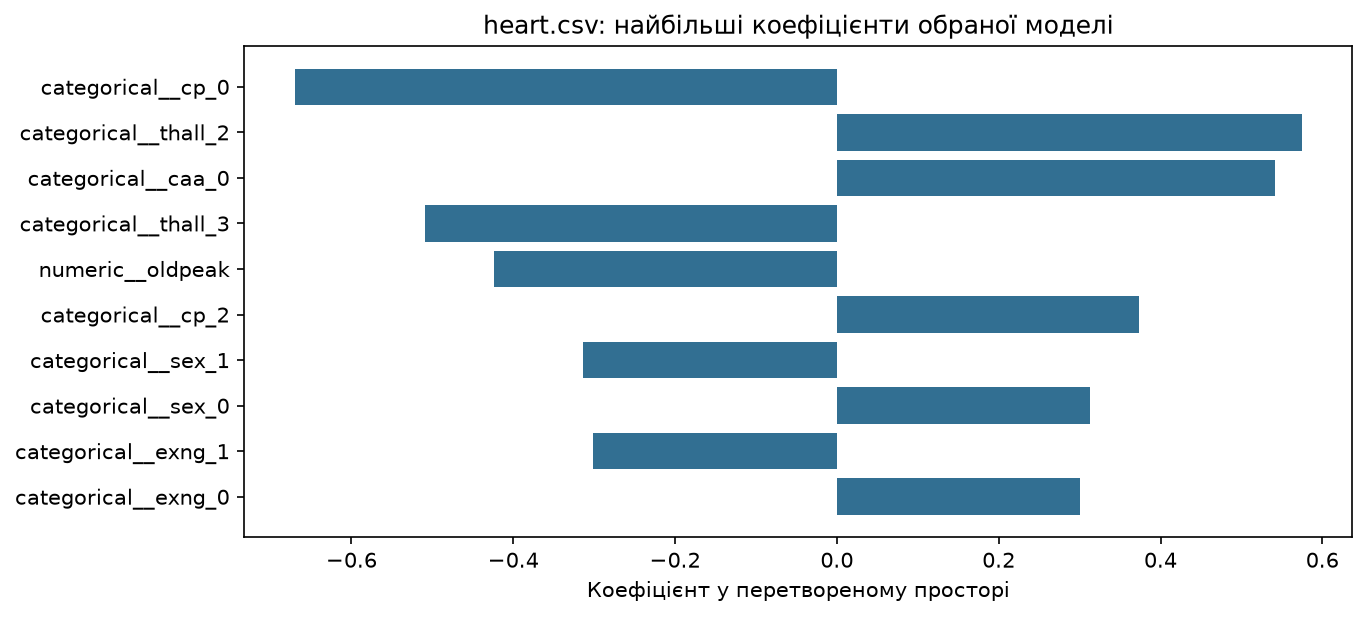

,source_row,age,trtbps,chol,thalachh,oldpeak,sex,cp,fbs,restecg,exng,slp,caa,thall,actual,predicted,decision_score
0,179,57,150,276,112,0.6,1,0,0,0,1,1,1,1,0,0,-2.599187
1,197,67,125,254,163,0.2,1,0,1,1,0,1,2,3,0,0,-0.970216
2,285,46,140,311,120,1.8,1,0,0,1,1,1,2,3,0,0,-3.161125
3,194,60,140,185,155,3.0,1,2,0,0,0,1,0,2,0,1,0.859066
4,188,50,140,233,163,0.6,1,2,0,1,0,1,1,3,0,0,-0.047096


In [7]:
theta_heart = heart_classification(heart_data)
heart_summary = read_result("heart_summary.json")
print("Обрана модель:", heart_summary["selected_model"])
print("Параметри:", heart_summary["selected_params"])
print("Розмір train / validation:", heart_summary["train_rows"], "/", heart_summary["validation_rows"])
display(pd.read_csv(OUTPUTS / "heart_model_selection.csv"))
display(pd.Series(heart_summary["validation"], name="Значення"))
display(pd.read_csv(OUTPUTS / "heart_classification_report.csv"))
display(Image(filename=str(FIGURES / "heart_confusion.png")))
display(Image(filename=str(FIGURES / "heart_roc.png")))
display(Image(filename=str(FIGURES / "heart_coefficients.png")))
display(pd.read_csv(OUTPUTS / "heart_validation.csv").head())

### Як читати метрики

Accuracy — частка правильних класів. Precision — наскільки точні позитивні передбачення для класу; recall — яку частку справжніх представників класу знайдено. F1 поєднує precision і recall. Macro F1 надає однакову вагу класам, weighted F1 враховує їхню чисельність. ROC-AUC оцінює ранжування класів за decision score; це не частка правильних відповідей. Коефіцієнти не встановлюють причинних медичних зв’язків. На 61 відкладеному записі оцінки мають обмежену статистичну стійкість.

## Additional (extra credit)

There are more files in the resources folder. Take a look at the. Visualize data in these files. Choose ML algorithm for building a model and making predictions for new data. Visualize the model.

Це необов’язковий додатковий пункт. Окрему бонусну модель не реалізовано; дві основні задачі вище очікують файлів.

## Machine learning analysis on texts

Predict text score (sentiment, holistic score, etc., any other target label) using machine learning algorithm you see best fit for the task. Choose kaggle dataset from available below. Display classification report (confusion matrix, accuracy, f1 score, etc.). 

- Learning Agency Lab - Automated Essay Scoring 2.0: predict holistic text score given full_text (student essays) https://www.kaggle.com/competitions/learning-agency-lab-automated-essay-scoring-2
- 100K Coursera's Course Reviews Dataset: predict the final rating (1 to 5) based on the text of the review https://www.kaggle.com/datasets/septa97/100k-courseras-course-reviews-dataset
- LLM - Detect AI Generated Text: predict the target label (0 being written by student and 1 being written by LLM) given the full text https://www.kaggle.com/competitions/llm-detect-ai-generated-text
- 42K+ Udemy Course Enrollment Information Dataset🔥: classify course categories using Title and Summary; compare text-only features against combined title-and-summary features https://www.kaggle.com/datasets/songseungwon/2020-udemy-courses-dataset
- TMDB 5000 Movie Dataset: movie classification based on description https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata?select=tmdb_5000_movies.csv



### Джерело й підготовка текстів

Використано рекомендований **100K Coursera’s Course Reviews**: оригінальний `reviews.csv` містить 107 018 рядків і поля Id, Review, Label. Класифікуємо оцінку **1–5 за Review**; Id та сама Label не є ознаками. CSV завантажено через публічний endpoint Kaggle й збережено локально, що прямо дозволено приміткою в шаблоні. `load_dataset()` читає цей файл без додаткової залежності kagglehub.

Перед поділом прибрано порожні відгуки, згруповано тексти без урахування регістру й пунктуації. Тексти з кількома різними оцінками вилучено як неоднозначно розмічені. Решту повторів прибрано. Цей крок документує зміну популяції: результат стосується очищених однозначно розмічених відгуків.

Виділено стратифіковані 20% на validation. Порівняно MultinomialNB, SGD із log-loss та LinearSVC через 3-фолдову CV лише на train. Ознаки — TF-IDF уніграм і біграм, до 20 000 ознак, min_df=3. TF-IDF входить до Pipeline і **заново навчається всередині кожного фолду**, щоб словник і IDF не отримували інформацію з перевірочних текстів.

Модель обирається за macro F1, бо рейтинг 5 значно переважає. Простий baseline завжди прогнозує найчастіший клас. Нижче наведено й його оцінки, щоб висока accuracy через дисбаланс не виглядала успіхом сама по собі.

Початковий розмір: (107018, 3)


,Id,Review,Label
0,0,good and interesting,5
1,1,"This class is very helpful to me. Currently, I...",5
2,2,like!Prof and TAs are helpful and the discussi...,5
3,3,Easy to follow and includes a lot basic and im...,5
4,4,Really nice teacher!I could got the point eazl...,4


Text CV: multinomial_nb, macro F1=0.2517


Text CV: sgd_logistic, macro F1=0.4148


Text CV: linear_svc, macro F1=0.3903


...

original_rows               107018
missing_rows_removed             0
empty_rows_removed               3
conflicting_rows_removed      7563
duplicates_removed            2904
rows_after_cleaning          96548
dtype: int64

Обрана модель: sgd_logistic
Розмір train / validation: 77238 / 19310


,model,cv_macro_f1,cv_std
0,sgd_logistic,0.414817,0.002384
1,linear_svc,0.390298,0.002801
2,multinomial_nb,0.251736,0.001093


accuracy             0.741067
macro_f1             0.414542
weighted_f1          0.716589
baseline_accuracy    0.727136
baseline_macro_f1    0.168403
Name: Значення, dtype: float64

,class,precision,recall,f1-score,support
0,1,0.390681,0.457023,0.421256,477.0
1,2,0.198305,0.267123,0.227626,438.0
2,3,0.263930,0.273834,0.268790,986.0
3,4,0.440468,0.201010,0.276045,3368.0
4,5,0.835021,0.927854,0.878993,14041.0
5,macro avg,0.425681,0.425369,0.414542,19310.0
6,weighted avg,0.711625,0.741067,0.716589,19310.0


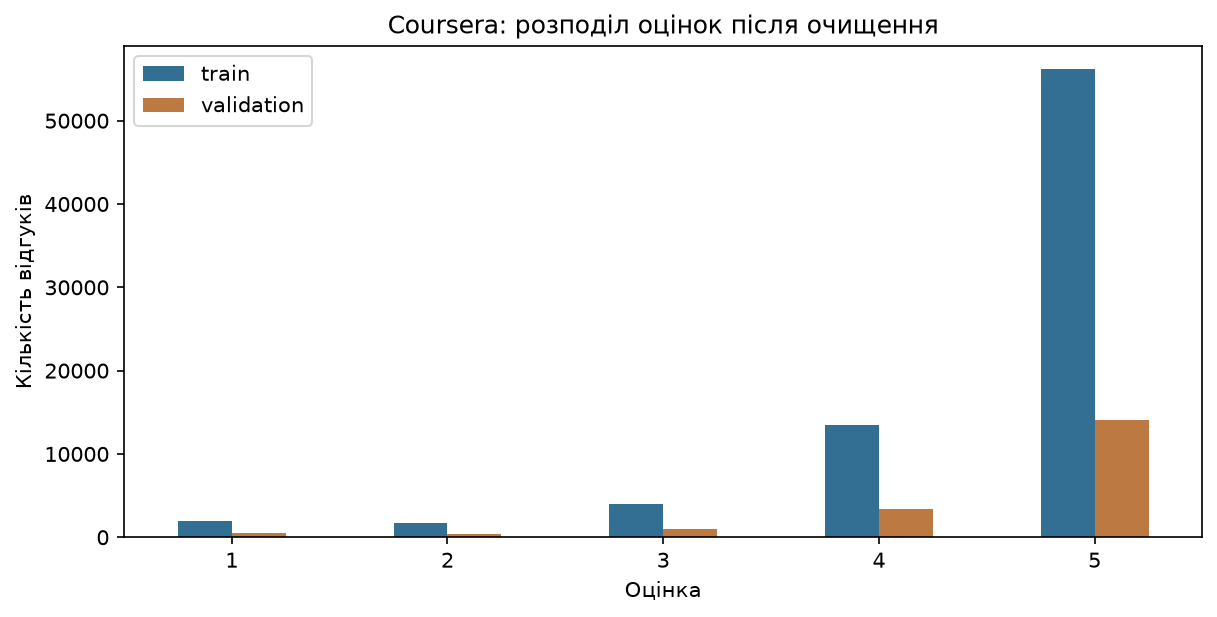

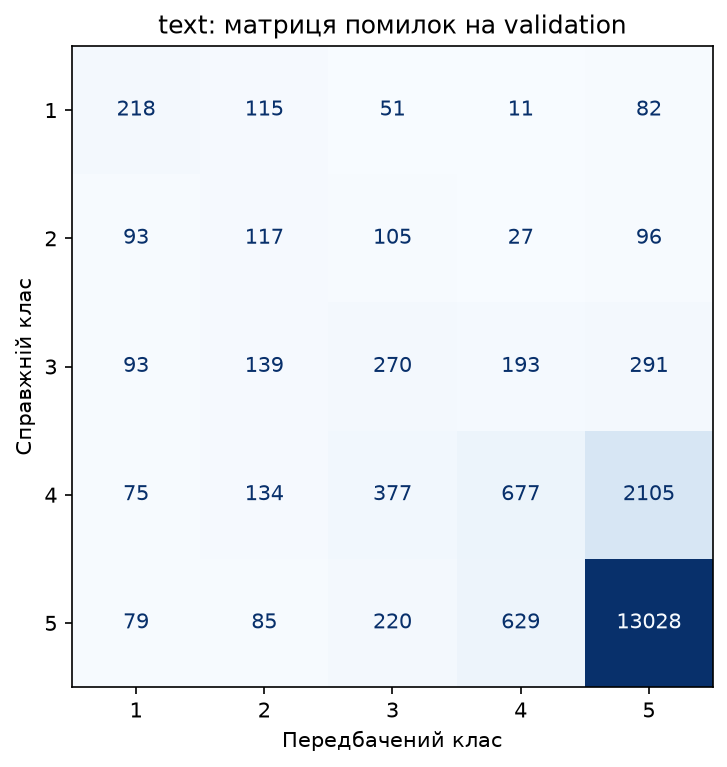

,label,terms
0,1,"[poor, boring, poorly, disappointed, bad, does..."
1,2,"[disappointed, basic, didn, boring, content, p..."
2,3,"[basic, content, ok, little, bit, needs, expec..."
3,4,"[bit, little, overall, good, better, stars, qu..."
4,5,"[excellent, thank, best, great, amazing, aweso..."


In [8]:
reviews = load_dataset()
print("Початковий розмір:", reviews.shape)
display(reviews.head())
classify_text_ml(reviews)
text_summary = read_result("text_summary.json")
print("Очищення:")
display(pd.Series(text_summary["cleaning"]))
print("Обрана модель:", text_summary["selected_model"])
print("Розмір train / validation:", text_summary["train_rows"], "/", text_summary["validation_rows"])
display(pd.read_csv(OUTPUTS / "text_model_selection.csv"))
display(pd.Series(text_summary["validation"], name="Значення"))
display(pd.read_csv(OUTPUTS / "text_classification_report.csv"))
display(Image(filename=str(FIGURES / "text_class_balance.png")))
display(Image(filename=str(FIGURES / "text_confusion.png")))
display(pd.DataFrame(read_result("text_top_terms.json")))

### Інтерпретація

П’ять оцінок утворюють порядкову шкалу, але ця постановка — багатокласова класифікація. За F1 помилки 1→2 та 1→5 не отримують окремої порядкової вартості. У матриці помилок видно, які оцінки плутаються. Модель із більшою macro F1 може мати нижчу accuracy, ніж прогнозування лише класу 5: це наслідок іншого балансу помилок, який потрібно показувати відкрито. Результат не слід переносити на всі тексти або на дані з іншої платформи без додаткової перевірки.

## Контроль поділу й збережені результати

Індекси train/validation, передбачення, метрики, коефіцієнти та результати вибору моделей збережено в `outputs/lab3/`; графіки — у `figures/lab3/`. Нижче перевірено, що множини рядків не перетинаються. Для текстів окремо перевірено відсутність однакових нормалізованих відгуків у двох частинах.

In [9]:
for name in ["co2", "heart", "text"]:
    split = read_result(f"{name}_split.json")
    assert set(split["train_rows"]).isdisjoint(split["validation_rows"])
    print(name, "— train і validation не перетинаються")
summary = write_summary()
print("Статус основних завдань:")
for name, result in summary.items():
    print(name, "—", result["status"])

co2 — train і validation не перетинаються
heart — train і validation не перетинаються
text — train і validation не перетинаються
Статус основних завдань:
co2 — completed
heart — completed
text — completed
ice_cream — waiting_for_teacher_file
power — waiting_for_teacher_file


## Джерела й запуск

- [Оригінальна умова](https://github.com/maxvonlancaster/ida-labs/blob/d9aa2577eec089206f4966569c8e3443ad419ba1/assignement-3.ipynb).
- [Coursera Reviews](https://www.kaggle.com/datasets/septa97/100k-courseras-course-reviews-dataset).
- [Лекція про лінійні моделі](https://github.com/maxvonlancaster/intelligent-data-analysis/blob/main/src/202-linear-classification.ipynb).
- `resources/lab3_sources.json` — походження й контрольні суми.

Повний запуск доступних частин: `python execute_notebook.py assignement-3.ipynb`. Скрипт: `python lab3.py`. Тести: `python -m unittest discover -s tests -v`. Два повідомлення про відсутні дані не є результатами виконання регресійних задач.